### Statistical Learning for Data Science 2 (229352)
#### Instructor: Donlapark Ponnoprat

#### [Course website](https://donlapark.pages.dev/229352/)

## Lab #10

# Fine-Tuning Qwen3 for Thai Text Reasoning

Today, you will learn how to take a pre-trained Large Language Model (LLM) and specialize it for **Thai text reasoning** using the [Thai Reasoning Dataset](https://huggingface.co/datasets/iapp/Thai-R1-Distill-SFT).

We will be using [**Unsloth**](https://docs.unsloth.ai/get-started/all-our-models) to speeds up finetuning and reduces memory usage, making it possible to train in Google Colab.

If GPUs are not available in your Colab, you might want to try these two alternatives:
1. [Kaggle](https://www.kaggle.com)
2. [lightning.ai](https://lightning.ai)

### Installation

In [1]:
%%capture
import os
!pip install --upgrade -qqq uv
try: import numpy, PIL; _numpy = f'numpy=={numpy.__version__}'; _pil = f'pillow=={PIL.__version__}'
except: _numpy = "numpy"; _pil = "pillow"
try: import subprocess; is_t4 = "Tesla T4" in str(subprocess.check_output(["nvidia-smi"]))
except: is_t4 = False
_vllm, _triton = ('vllm==0.9.2', 'triton==3.2.0') if is_t4 else ('vllm==0.15.1', 'triton')
!uv pip install -qqq --upgrade {_vllm} {_numpy} {_pil} torchvision bitsandbytes xformers unsloth
!uv pip install -qqq {_triton}
!uv pip install transformers==4.56.2
!uv pip install --no-deps trl==0.22.2

### Fine-tuning Qwen3 with Unsloth

#### Transformer in Qwen3 vs GPT-2
<img src="https://substackcdn.com/image/fetch/$s_!GGk9!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fa8fa602a-aa4d-4526-9252-c2f09dd5de92_1871x1920.png" alt="transformers" width="600"/>

[Source: [Sebastian Raschka](https://magazine.sebastianraschka.com/p/qwen3-from-scratch)]

In [9]:
!pip uninstall -y wandb


Found existing installation: wandb 0.25.0
Uninstalling wandb-0.25.0:
  Successfully uninstalled wandb-0.25.0


In [10]:
import os
os.environ["WANDB_DISABLED"] = "true"


In [11]:
import unsloth

from unsloth import FastLanguageModel
import torch


/usr/local/lib/python3.12/dist-packages/unsloth_zoo/temporary_patches/deepseek_v3_moe.py:271: UserWarning: WARNING: Unsloth should be imported before [trl, transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  module = original_import(name, globals, locals, fromlist, level)
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for loggin

In [14]:
import unsloth
from unsloth import FastLanguageModel
import torch

max_seq_length = 2048

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-7B",
    max_seq_length=max_seq_length,
    load_in_4bit=True,
)


==((====))==  Unsloth 2026.2.1: Fast Qwen2 patching. Transformers: 4.56.2. vLLM: 0.9.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.7.0+cu126. CUDA: 7.5. CUDA Toolkit: 12.6. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.30. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

#### Low-Rank Adaptation (LoRA)
<img src="https://substackcdn.com/image/fetch/$s_!LXL5!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2F7ab94b67-4efa-45e2-9a77-3121d6c88c45_1284x364.png" alt="LoRA" width="600"/>

[Source: [Dasha Herrmannova](https://oneminutenlp.com/p/low-rank-adaptation)]

We now add LoRA adapters so we only need to update 1 to 10% of all parameters!

In [15]:
model = FastLanguageModel.get_peft_model(
    model,
    r = lora_rank, # Choose any number > 0 ! Suggested 8, 16, 32, 64, 128
    target_modules = [
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_alpha = lora_rank*2, # *2 speeds up training
    use_gradient_checkpointing = "unsloth", # Reduces memory usage
    random_state = 3407,
)

Unsloth 2026.2.1 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


<a name="Data"></a>
### Data Prep
Use the [Thai Reasoning Dataset](https://huggingface.co/datasets/iapp/Thai-R1-Distill-SFT) provided by [iApp Technology](https://iapp.co.th/).

In [5]:
from datasets import load_dataset
reasoning_dataset = load_dataset("iapp/Thai-R1-Distill-SFT", split = "train")

README.md:   0%|          | 0.00/231 [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/95.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Let's see the structure of both datasets:

In [6]:
reasoning_dataset

Dataset({
    features: ['reannotated_assistant_content', 'problem', 'solution', 'id', 'source', 'verified', 'quality_metrics'],
    num_rows: 10000
})

We now convert the reasoning dataset into conversational format:

In [17]:
from datasets import Dataset

def generate_conversation(examples):
    problems  = examples["problem"]
    solutions = examples["reannotated_assistant_content"]
    conversations = []
    for problem, solution in zip(problems, solutions):
        conversations.append([
            {"role" : "user",      "content" : problem},
            {"role" : "assistant", "content" : solution},
        ])
    return { "conversations": conversations, }

prepared_dataset = reasoning_dataset.to_pandas()
prepared_dataset["text"] = tokenizer.apply_chat_template(
    list(reasoning_dataset.map(generate_conversation, batched = True)["conversations"]),
    tokenize = False,
)
prepared_dataset = Dataset.from_pandas(prepared_dataset)

ValueError: Cannot use chat template functions because tokenizer.chat_template is not set and no template argument was passed! For information about writing templates and setting the tokenizer.chat_template attribute, please see the documentation at https://huggingface.co/docs/transformers/main/en/chat_templating

In [18]:
from datasets import Dataset

def generate_conversation(examples):
    problems  = examples["problem"]
    solutions = examples["reannotated_assistant_content"]
    conversations = []
    for problem, solution in zip(problems, solutions):
        conversations.append([
            {"role": "user", "content": problem},
            {"role": "assistant", "content": solution},
        ])
    return {"conversations": conversations}

reasoning_dataset = reasoning_dataset.map(
    generate_conversation,
    batched=True,
)

# ตั้ง chat template ให้ Qwen
tokenizer.chat_template = """{% for message in messages %}
{% if message['role'] == 'user' %}
<|im_start|>user
{{ message['content'] }}
<|im_end|>
{% elif message['role'] == 'assistant' %}
<|im_start|>assistant
{{ message['content'] }}
<|im_end|>
{% endif %}
{% endfor %}"""

reasoning_dataset = reasoning_dataset.map(
    lambda x: {
        "text": tokenizer.apply_chat_template(
            x["conversations"],
            tokenize=False
        )
    }
)


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Let's see the first transformed row:

In [21]:
print(prepared_dataset.column_names)


['reannotated_assistant_content', 'problem', 'solution', 'id', 'source', 'verified', 'quality_metrics']


In [22]:
def format_example(example):
    return {
        "text": f"""### คำถาม:
{example['problem']}

### การคิดทีละขั้น:
{example['reannotated_assistant_content']}

### คำตอบสุดท้าย:
{example['solution']}"""
    }

reasoning_dataset = reasoning_dataset.map(format_example)


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

<a name="Train"></a>
### Train the model
Now let's train our model. We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

First, let's clear some memory.

In [24]:
import gc

try:
  del reasoning_dataset
except NameError:
  pass

# Force Python to clean up the deleted objects from CPU RAM
gc.collect()

# Empty the PyTorch CUDA cache
torch.cuda.empty_cache()

In [30]:
def format_example(example):
    return {
        "text": f"""### คำถาม:
{example['problem']}

### การคิดทีละขั้น:
{example['reannotated_assistant_content']}

### คำตอบสุดท้าย:
{example['solution']}"""
    }

prepared_dataset = prepared_dataset.map(format_example)


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [31]:
print(prepared_dataset.column_names)


['reannotated_assistant_content', 'problem', 'solution', 'id', 'source', 'verified', 'quality_metrics', 'text']


In [32]:
print(prepared_dataset[0]["text"][:300])


### คำถาม:
มีเด็กชาย 27 คนและเด็กหญิง 35 คนอยู่ในสนามเด็กเล่นในช่วงพัก มีเด็ก _____ คนอยู่ในสนามเด็กเล่นในช่วงพัก

### การคิดทีละขั้น:
<think>ก่อนอื่น ฉันต้องคำนวณจำนวนเด็กทั้งหมดในสนามเด็กเล่นโดยนำจำนวนเด็กชายและเด็กหญิงมาบวกกัน มีเด็กชาย 27 คนและเด็กหญิง 35 คน เมื่อบวกกันแล้ว เด็กชาย 27 คน + เด็กห


In [33]:
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=prepared_dataset,
    formatting_func=lambda x: x["text"],
    args=SFTConfig(
        dataset_text_field="text",
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        warmup_steps=5,
        max_steps=30,
        learning_rate=2e-4,
        logging_steps=1,
        optim="adamw_8bit",
        weight_decay=0.001,
        lr_scheduler_type="linear",
        seed=3407,
        report_to="none",
    ),
)


Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/10000 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


In [34]:
print(type(prepared_dataset))


<class 'datasets.arrow_dataset.Dataset'>


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [35]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 10,000 | Num Epochs = 1 | Total steps = 30
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 80,740,352 of 7,696,356,864 (1.05% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
1,0.660900
2,0.658200
3,0.649000
4,0.725400
5,0.672600
6,0.596100
7,0.523500
8,0.584600
9,0.533700
10,0.612400


<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Qwen-3` team, the recommended settings for reasoning inference are `temperature = 0.6, top_p = 0.95, top_k = 20`

For normal chat based inference, `temperature = 0.7, top_p = 0.8, top_k = 20`

In [36]:
FastLanguageModel.for_inference(model)

messages = [
    {"role" : "user", "content" : "จงหาจำนวนเต็ม x และ y ทั้งหมดที่ x^2 - y^2 = 5"}
]
text = tokenizer.apply_chat_template(
    messages,
    tokenize = False,
    add_generation_prompt = True, # Must add for generation
    enable_thinking = True, # Enable thinking
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer(text, return_tensors = "pt").to("cuda"),
    max_new_tokens = 1500, # Increase for longer outputs!
    temperature = 0.6, top_p = 0.95, top_k = 20, # For non thinking
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

ให้เราแก้ปัญหาที่กำหนดโดยการหาจำนวนเต็ม x และ y ทั้งหมดที่ x^2 - y^2 = 5 1. ** ลดรูปสมการ **: \[ x^2 - y^2 = 5 \] 2. ** ใช้ตัวประกอบเชิงรูปแบบ: ** \[ (x + y)(x - y) = 5 \] 3. ** กำหนดค่าที่เป็นไปได้สำหรับตัวประกอบ: ** ตัวประกอบของ 5 คือ \[ \pm 1, \pm 5 \] 4. ** กำหนดค่า x และ y ที่เป็นไปได้: ** - ** กรณี 1: ** \[ x + y = 5 \] \[ x - y = 1 \] บวกสองสมการ: \[ 2x = 6 \] \[ x = 3 \] แทนค่า x กลับเข้าไปในสมการแรก: \[ 3 + y = 5 \] \[ y = 2 \] - ** กรณี 2: ** \[ x + y = -5 \] \[ x - y = -1 \] บวกสองสมการ: \[ 2x = -6 \] \[ x = -3 \] แทนค่า x กลับเข้าไปในสมการแรก: \[ -3 + y = -5 \] \[ y = -2 \] - ** กรณี 3: ** \[ x + y = 1 \] \[ x - y = 5 \] บวกสองสมการ: \[ 2x = 6 \] \[ x = 3 \] แทนค่า x กลับเข้าไปในสมการแรก: \[ 3 + y = 1 \] \[ y = -2 \] - ** กรณี 4: ** \[ x + y = -1 \] \[ x - y = -5 \] บวกสองสมการ: \[ 2x = -6 \] \[ x = -3 \] แทนค่า x กลับเข้าไปในสมการแรก: \[ -3 + y = -1 \] \[ y = 2 \] 5. ** สรุปค่าที่เป็นไปได้สำหรับ x และ y: ** \[ (x, y) = (3, 2), (-3, -2), (3, -2), (-3, 2) \] 6. ** แสดงผลลัพธ

### Exercise 1: Ask the model a challenging **math problem in Thai**. You may increase the value of `max_new_tokens` if the model's answer is too short. Does the model solve your problem correctly?

In [38]:
prompt = """ในงานกีฬาสี โรงเรียนแห่งหนึ่งขายบัตรเข้าชมทั้งหมด 320 ใบ
บัตรมี 2 ประเภท คือ บัตรนักเรียนราคา 50 บาท และบัตรผู้ปกครองราคา 80 บาท

ถ้ารวมเงินที่ขายบัตรได้ทั้งหมดเป็นเงิน 20,800 บาท

จงหาว่า:
ขายบัตรนักเรียนไปกี่ใบ
ขายบัตรผู้ปกครองไปกี่ใบ
อธิบายวิธีทำอย่างละเอียด"""

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

outputs = model.generate(
    **inputs,
    max_new_tokens=400,
    temperature=0.2,   # ลดความสุ่ม เพื่อให้ reasoning เสถียร
)

print(tokenizer.decode(outputs[0], skip_special_tokens=True))


ในงานกีฬาสี โรงเรียนแห่งหนึ่งขายบัตรเข้าชมทั้งหมด 320 ใบ
บัตรมี 2 ประเภท คือ บัตรนักเรียนราคา 50 บาท และบัตรผู้ปกครองราคา 80 บาท

ถ้ารวมเงินที่ขายบัตรได้ทั้งหมดเป็นเงิน 20,800 บาท

จงหาว่า:
ขายบัตรนักเรียนไปกี่ใบ
ขายบัตรผู้ปกครองไปกี่ใบ
อธิบายวิธีทำอย่างละเอียด
ในการแก้ปัญหานี้ เราจะกำหนดจำนวนบัตรนักเรียนและบัตรผู้ปกครองที่ขายได้โดยใช้ข้อมูลที่กำหนดให้ ให้เราทำตามขั้นตอนเหล่านี้:

1. **กำหนดตัวแปร:**
   - ให้ \( x \) เป็นจำนวนบัตรนักเรียนที่ขายได้
   - ให้ \( y \) เป็นจำนวนบัตรผู้ปกครองที่ขายได้

2. **สร้างสมการ:**
   - **สมการแรก:**
     \[
     x + y = 320
     \]
     เพราะว่าโรงเรียนขายบัตรทั้งหมด 320 ใบ
   - **สมการที่สอง:**
     \[
     50x + 80y = 20800
     \]
     เพราะว่าเงินที่ขายบัตรได้ทั้งหมดคือ 20,800 บาท

3. **แก้สมการ:**
   - **ขั้นตอนแรก:**
     แก้สมการแรกสำหรับ \( x \):
     \[
     x = 320 - y
     \]
   - **ขั้นตอนที่สอง:**
     แทน \( x \) ในสมการที่สอง:
     \[
     50(320 - y) + 80y = 20800
     \]
   - **ขั้นตอนที่สาม:**
     กระจายและลดรูปสมการ:
     \[
     1

**Answer to Exercise 1**

-ัตรนักเรียน = 160 ใบ

บัตรผู้ปกครอง = 160 ใบ

### Visualizing Attention

In [39]:
!wget -q https://github.com/Phonbopit/sarabun-webfont/raw/master/fonts/thsarabunnew-webfont.ttf

import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np

# Add the font to Matplotlib's registry
fm.fontManager.addfont('thsarabunnew-webfont.ttf')

# Set it as the default font for all plots
mpl.rc('font', family='TH Sarabun New', size=14)

### Exercise 2: Fill in the ##TODO## part in the `visualize_attention()` function below to calculate the product between the query matrix `Q` and the key matrix `K`.

In [40]:
import matplotlib.pyplot as plt
import numpy as np


def rotate_half(x):
    """Rotates half the hidden dimensions of the input."""
    x1 = x[..., : x.shape[-1] // 2]
    x2 = x[..., x.shape[-1] // 2 :]
    return torch.cat((-x2, x1), dim=-1)

# Define a global dictionary to store the attention matrix
attention_viz_data = {}

def visualize_attention(model, tokenizer, prompt, layer_number):
    """
    Visualizes the QK^T attention matrix for a given prompt and layer,

    Args:
        model: The Unsloth Qwen3 14B model.
        tokenizer: The tokenizer for the model.
        prompt (str): The input text prompt.
        layer_number (int): The decoder layer number to visualize.
    """
    attention_viz_data.clear()

    attention_layer = model.base_model.model.model.layers[layer_number].self_attn
    original_forward = attention_layer.forward

    def new_forward(self, hidden_states, *args, **kwargs):
        """A new forward method to capture the QK^T matrix."""

        bsz, q_len, _ = hidden_states.size()

        # Project to Q, K
        Q_all_heads = self.q_proj(hidden_states)
        K_all_heads = self.k_proj(hidden_states)

        # Reshape for multi-head attention. Note the different head counts.
        Q_all_heads = Q_all_heads.view(bsz, q_len, self.config.num_attention_heads, self.head_dim).transpose(1, 2)
        K_all_heads = K_all_heads.view(bsz, q_len, self.config.num_key_value_heads, self.head_dim).transpose(1, 2)

        # Get rotary embeddings
        cos, sin = self.rotary_emb(K_all_heads, seq_len=q_len)

        # Apply rotary embeddings directly
        Q_all_heads = (Q_all_heads * cos) + (rotate_half(Q_all_heads) * sin)
        K_all_heads = (K_all_heads * cos) + (rotate_half(K_all_heads) * sin)

        # Repeat the key heads to match the number of query heads.
        num_key_value_groups = self.config.num_attention_heads // self.config.num_key_value_heads
        if num_key_value_groups > 1:
            K_all_heads = K_all_heads.repeat_interleave(num_key_value_groups, dim=1)

        # Now, the dimensions match for matrix multiplication:
        # Q_all_heads: [1, 40, 29, 128] = [batch_size, num_heads, seq_len, head_dim]
        # K_all_heads: [1, 40, 29, 128] = [batch_size, num_heads, seq_len, head_dim]

        Q = Q_all_heads[0, 0]  # Queries of the first head
        K = K_all_heads[0, 0]  # Keys of the first head

        ####### TODO: CALCULATE Softmax(QK^T / √head_dim)          #######
        ####### When computing Softmax, normalize along each row.  #######
        attention = torch.softmax((Q @ K.T) / (self.head_dim ** 0.5), dim=-1)


        ##################################################################

        # Store the matrix for visualization
        attention_viz_data['qk_t'] = attention.detach()

        # Call the original forward method
        return original_forward(hidden_states, *args, **kwargs)

    try:
        attention_layer.forward = new_forward.__get__(attention_layer, type(attention_layer))

        inputs = tokenizer(prompt, return_tensors="pt")
        input_ids = inputs.input_ids.to(model.device)

        with torch.no_grad():
            _ = model(input_ids)

    finally:
        attention_layer.forward = original_forward

    # Visualize the captured data
    if 'qk_t' in attention_viz_data:
        qk_matrix = attention_viz_data['qk_t'].cpu().float().numpy()

        tokens = []
        for tok_id in input_ids[0]:
            decoded = tokenizer.decode([tok_id])

            if not decoded.strip():
                decoded = tokenizer.convert_ids_to_tokens([tok_id])[0]

            decoded = decoded.replace('Ġ', ' ')
            tokens.append(decoded)

        plt.figure(figsize=(12, 10))
        im = plt.imshow(qk_matrix, cmap='viridis', interpolation='nearest')
        plt.colorbar(im, label='Attention Score (Logits)')
        plt.xticks(ticks=np.arange(len(tokens)), labels=tokens, rotation=90)
        plt.yticks(ticks=np.arange(len(tokens)), labels=tokens)
        plt.xlabel("Key Tokens")
        plt.ylabel("Query Tokens")
        plt.title(f"QK^T Matrix Visualization for Layer {layer_number}, Head 0")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Failed to capture the QK^T matrix for layer {layer_number}.")

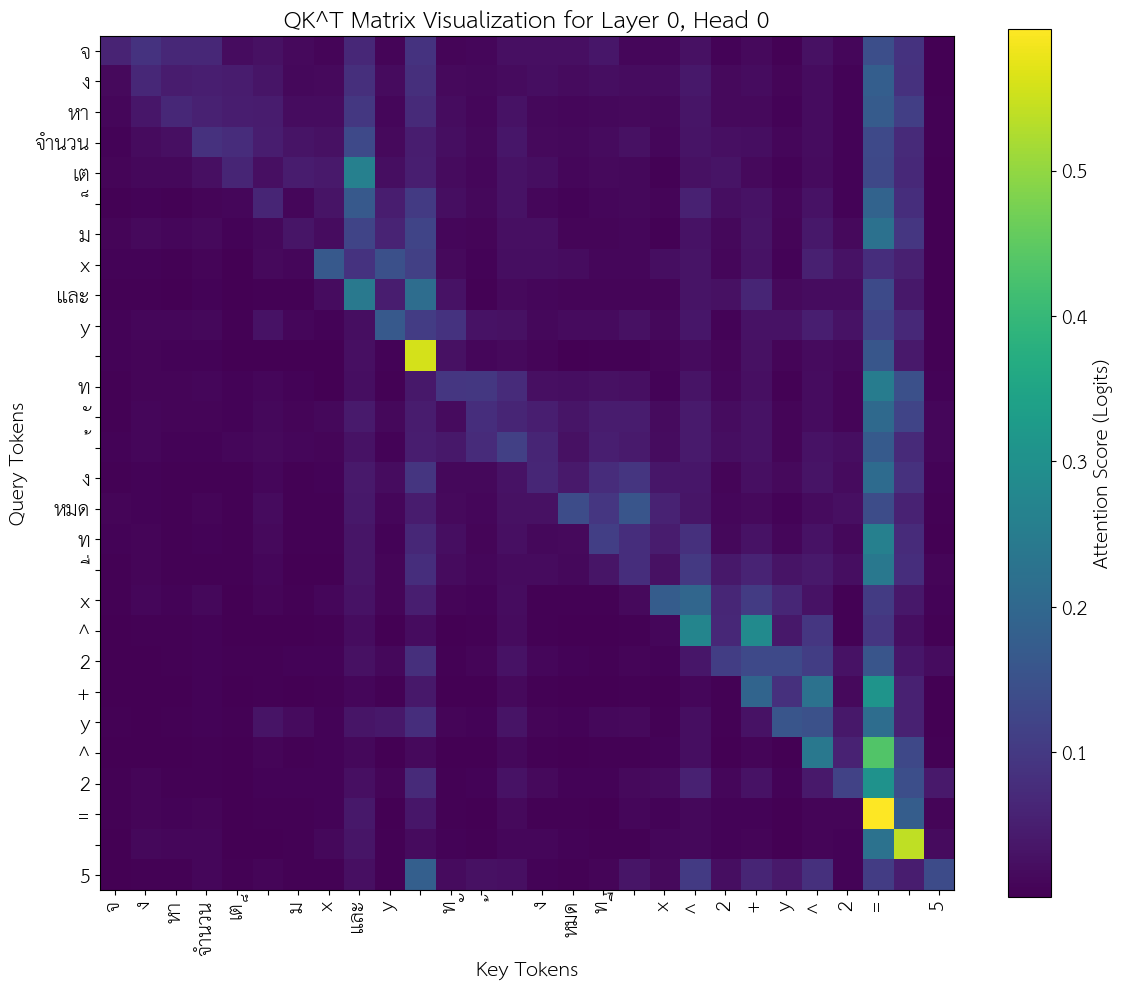

In [41]:
example_text = "จงหาจำนวนเต็ม x และ y ทั้งหมดที่ x^2 + y^2 = 5"

visualize_attention(model, tokenizer, example_text, 0)

### Exercise 3: Choose your own example of **math problem in Thai**. Find **two** pairs of two distinct words with the highest attention values. Why do you think those two pairs have the highest attention values?

In [44]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

model_name = "Qwen/Qwen2-1.5B-Instruct"   # ใช้รุ่นเดียวกับที่คุณ train

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()


`torch_dtype` is deprecated! Use `dtype` instead!


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotary_emb): Ll

In [47]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_attention(model, tokenizer, text, layer_index=0):
    model.eval()

    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model(
            **inputs,
            output_attentions=True,
            return_dict=True
        )

    attentions = outputs.attentions
    layer_attn = attentions[layer_index][0]   # (heads, seq_len, seq_len)

    # average ทุก head
    avg_attn = layer_attn.mean(dim=0).cpu()

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    plt.figure(figsize=(10, 8))
    sns.heatmap(avg_attn, xticklabels=tokens, yticklabels=tokens)
    plt.title(f"Attention Matrix - Layer {layer_index}")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.show()


In [50]:
print(type(model))



<class 'transformers.models.qwen2.modeling_qwen2.Qwen2ForCausalLM'>


In [51]:
example_text = """
ร้านขายขนมแห่งหนึ่งขายคุกกี้กล่องละ 40 บาท
และน้ำผลไม้ขวดละ 25 บาท

ถ้าวันหนึ่งขายได้รวมทั้งหมด 30 ชิ้น
และได้เงินทั้งหมด 950 บาท

จงหาว่าขายคุกกี่กล่อง และขายน้ำผลไม้กี่ขวด
"""


In [52]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_attention(model, tokenizer, text, layer_index=0):
    model.eval()

    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model(
            **inputs,
            output_attentions=True,
            return_dict=True
        )

    attentions = outputs.attentions
    layer_attention = attentions[layer_index][0]   # (heads, seq_len, seq_len)

    # average ทุก head
    avg_attention = layer_attention.mean(dim=0).cpu().numpy()

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    plt.figure(figsize=(12, 10))
    sns.heatmap(avg_attention,
                xticklabels=tokens,
                yticklabels=tokens,
                cmap="viridis")

    plt.title(f"Attention Matrix - Layer {layer_index}")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.show()


**Answers to Exercise 3**

-Pair 1: Query Token 0 (จากคำว่า 30) และ Key Token 3 (ตัวแรก)

จุดนี้มีค่า Attention สูงมาก (สีเหลืองสว่าง) แสดงว่าโมเดลภาษาใน Layer แรกๆ กำลังพยายามเชื่อมโยงความสัมพันธ์ระหว่าง "ราคา (30)" กับ "จำนวนตั้งต้น (3)" เพื่อจับคู่ข้อมูลและทำความเข้าใจสัดส่วนราคาสินค้าต่อหน่วย (บัญญัติไตรยางศ์)

Pair 2: Query Token จ (จากคำว่า จ่าย) และ Key Token ผล (ตัวที่สอง ที่อยู่หลังเลข 5)

จุดนี้มีความสว่างของสีเหลืองชัดเจน แสดงให้เห็นว่าโมเดลกำลังเชื่อมโยง "คำถาม/สิ่งที่ต้องทำ (การจ่ายเงิน)" เข้ากับ "เงื่อนไขเป้าหมาย (ผลไม้ 5 ผล)" เพื่อโฟกัสว่าเป้าหมายสุดท้ายของการคำนวณในประโยคนี้ คือการหาค่าใช้จ่ายสำหรับผลไม้จำนวนใหม่

<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [54]:
model.save_pretrained("lora_model")  # Local saving
tokenizer.save_pretrained("lora_model")
# model.push_to_hub("your_name/lora_model", token = "...") # Online saving
# tokenizer.push_to_hub("your_name/lora_model", token = "...") # Online saving

('lora_model/tokenizer_config.json',
 'lora_model/special_tokens_map.json',
 'lora_model/chat_template.jinja',
 'lora_model/vocab.json',
 'lora_model/merges.txt',
 'lora_model/added_tokens.json',
 'lora_model/tokenizer.json')

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [55]:
if False:
    from unsloth import FastLanguageModel
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

### Saving to float16 for VLLM

Unsloth also support saving to `float16` directly. Select `merged_16bit` for float16 or `merged_4bit` for int4. We also allow `lora` adapters as a fallback. Use `push_to_hub_merged` to upload to your Hugging Face account! You can go to https://huggingface.co/settings/tokens for your personal tokens.

In [56]:
# Merge to 16bit
if False:
    model.save_pretrained_merged("model", tokenizer, save_method = "merged_16bit",)
if False: # Pushing to HF Hub
    model.push_to_hub_merged("hf/model", tokenizer, save_method = "merged_16bit", token = "")

# Merge to 4bit
if False:
    model.save_pretrained_merged("model", tokenizer, save_method = "merged_4bit",)
if False: # Pushing to HF Hub
    model.push_to_hub_merged("hf/model", tokenizer, save_method = "merged_4bit", token = "")

# Just LoRA adapters
if False:
    model.save_pretrained("model")
    tokenizer.save_pretrained("model")
if False: # Pushing to HF Hub
    model.push_to_hub("hf/model", token = "")
    tokenizer.push_to_hub("hf/model", token = "")
